# Lab 8
## Task 1
Claim 1: "A night in Stockholm costs 1,791." 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']
listings = pd.read_csv('../data/listings_clean.csv', parse_dates=date_columns)
print(listings.shape)

(4574, 73)


In [6]:
listings["price"].describe()

count     2957.000000
mean      2327.643382
std       2160.353619
min        120.000000
25%       1071.120000
50%       1791.000000
75%       3003.800000
max      40000.000000
Name: price, dtype: float64

In [9]:
listings["price_quote_price_per_night"].describe()

count     2957.000000
mean      2327.643382
std       2160.353619
min        120.000000
25%       1071.120000
50%       1791.000000
75%       3003.800000
max      40000.000000
Name: price_quote_price_per_night, dtype: float64

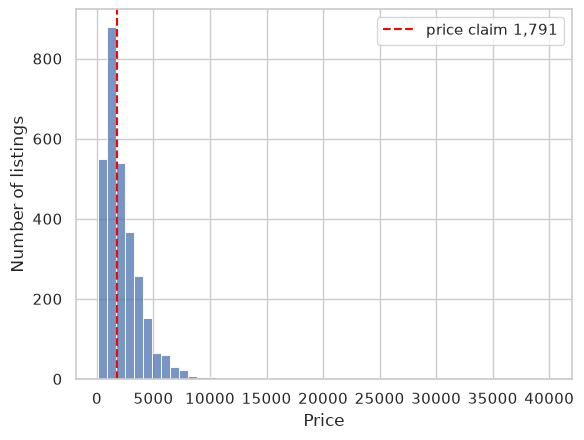

In [12]:
fig, ax = plt.subplots()
sns.histplot(data=listings, x='price', bins=50, ax=ax)

ax.set_title('')
ax.set_xlabel('Price')
ax.set_ylabel('Number of listings')

price_claim = 1791
ax.axvline(price_claim, color='red', linestyle='--', label=f'price claim {price_claim:,.0f}')

ax.legend()

plt.show()

In [15]:
missing_prices = listings["price"].isna().sum()
missing_prices

np.int64(1617)

### The data
Claimed price: 1791  
Median: 1791  
Mean: 2327  
Missing prices: 1617

### Evaluation
#### Claim: 
"A night in Stockholm costs 1,791"   

#### Verdict: 
Does not hold. It is true that the median price for the Stockholm Airbnb listings dataset is 1791, but the claim does not specify a measure (mean, median) or being about Airbnb listings at all, or even accommodation. There is also the aspect of the price outliers, since a couple of listings have a very high price. The outliers make the mean higher. The claim does not specify if these outliers should be taken into consideration or not. The claim needs to be more precise.

There is also the aspect of the missing prices. Not all of the listings have a price, 1617 of them do not. This is a significant amount. So given that there are that many listings that we do not have a price for, it cannot certainly be said that the mean or median values are representative of the reality, given that there are many listings that are not accounted for with a price.

#### New sentence: 
"The median price per night for an Airbnb listing in Stockholm is 1,791, for the listings that we have a price for".

## Task 2

Claim 2: "The listings with a perfect 5.00 rating are the best in Stockholm."

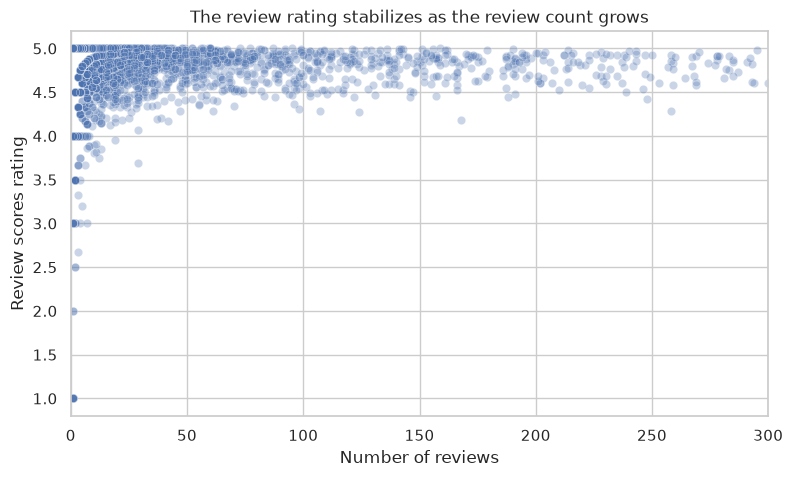

In [20]:
# Chart from lab 7 part 2
has_reviews = listings[listings["has_reviews"]]

x_limit = 300
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=has_reviews, x='number_of_reviews', y='review_scores_rating', alpha=0.3, ax=ax)
ax.set_xlim(0, x_limit)

ax.set_title('The review rating stabilizes as the review count grows')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Review scores rating')

plt.show()

In [27]:
review_threshold = 50
perfect_rating_score = 5.0
above_threshold = has_reviews[has_reviews["number_of_reviews"] > review_threshold]
above_threshold_and_perfect_rating = above_threshold[above_threshold["review_scores_rating"] == perfect_rating_score]
above_threshold_and_perfect_value = above_threshold[above_threshold["review_scores_value"] == perfect_rating_score]
above_threshold_and_perfect_rating
above_threshold_and_perfect_value

,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_profile_id,...,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,days_since_review,has_reviews,shared_bath,bathrooms_count
3624,1483354100594786139,https://www.airbnb.com/rooms/1483354100594786139,20260925011206,2026-09-27,NaN,"Cosy apartment in the heart of Old Town, Stock...",Stay in a gem from 1556 in Stockholm’s Old Tow...,https://a0.muscache.com/pictures/hosting/Hosti...,134344766,1483354102689718896,...,5.0,1,1,0,0,4.51,1.0,True,False,1.0


Draft thoughts
* How recent are the reviews?
* Rating vs value
* Not all listings have reviews - there might be some great ones that we do not know of
* Not every guest leaves a review

New claim:
Out of all the listings that have reviews, the ones that have a review count greater than 50 and a review score above 4.8 are likely to be a good place to stay

## Task 3
Claim: "The market has grown: only 131 listings started in 2016, but 610 in 2024."

In [54]:
listings["first_review_year"] = listings["first_review"].dt.year
no_year_count = listings["first_review_year"].isna().sum()

listings.groupby("first_review_year").size()

first_review_year
2011.0      2
2012.0     12
2013.0     26
2014.0     51
2015.0    116
2016.0    131
2017.0    148
2018.0    191
2019.0    234
2020.0     96
2021.0    159
2022.0    332
2023.0    565
2024.0    610
2025.0    542
2026.0    715
dtype: int64

It is true that there are 131 listings with the year 2016 and 610 listings with the year 2024. That, however, does not make the claim true.

Reasons: 
* The only year data we have is from first_review - the date for the first review is not always the same as the start date. What if the listing was created one year but got a its first review another year? 
* The listings that do not have any reviews are not counted at all
* Survivorship bias - completely removed listings are also removed from the count. The data can only show the listings that still remain today.
* Side note: the current year 2026 is not yet finished, so there is not data for the whole of 2026

Verdict:   
Does not hold, the listing start year cannot be reliably determined with the data that is available.

New sentence:   
Out of the listings that still remain today, 131 of them were first reviewed in 2016 and 610 were first reviewed in 2024.

## Task 4
Claim 4: "Most hosts in Stockholm are professional companies with many listings."

In [42]:
host_columns = listings[["host_listings_count", "host_id", "calculated_host_listings_count"]]
host_columns

,host_listings_count,host_id,calculated_host_listings_count
0,2,784312,2
1,2,412283,2
2,2,784312,2
3,3,1432722,2
4,1,1322033,1
...,...,...,...
4569,2,24056977,2
4570,11,713035605,1
4571,1,430540839,1
4572,2,672067666,1
